# COS30082 Project – Part 1: Independent CNN models (crop category)

Three **independent** CNNs (ResNet-50, EfficientNet-B0, ConvNeXt-Tiny) are each fine-tuned to predict the **crop category** (55 classes) on DPD-Small.

Training setup: up to **30 epochs**, **early stopping (patience 10)** monitored on the **seen test set (used as the validation set)**, best model saved, and train-vs-validation accuracy curves plotted per model.

**Data (Google Drive):** open https://drive.google.com/drive/folders/1h92MzUQc2HIm5dyGLGqmglw5Gb-xQF5r , right-click the folder → *Organize* → *Add shortcut* → *My Drive*. The notebook then finds `DPD_Small_clean` automatically.

Evaluation on the *seen* and *unseen* test sets:
- **Top-N accuracy** (N = 1, 3, 5)
- **Harmonic mean** of seen and unseen accuracy: `H = 2·S·U / (S + U)`
- **Confusion matrix** (seen and unseen) per model

Set the runtime to **GPU** (Runtime → Change runtime type) before running.

In [ ]:
!pip -q install timm

## 1. Configuration
Pick the dataset version (`DPD_Small_clean` is the cleaned version, `DPD_Small` the original). `drive_root` is where the shared folder (or its shortcut) lives in your Drive; the version folder is searched for beneath it.

In [ ]:
import os, re, glob, json, time, random, shutil
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from PIL import Image
import timm
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

CFG = dict(
    drive_root    = "/content/drive/MyDrive",      # searched for the version folder (use the exact folder path to speed it up)
    version       = "DPD_Small_clean",    # or "DPD_Small"
    out_dir       = "/content/drive/MyDrive/DPD_runs/crop_independent",
    copy_local    = True,                 # copy images to local disk (much faster than Drive)
    batch_size    = 64,
    epochs        = 30,
    patience      = 10,                   # early stopping on seen-set (validation) Top-1
    workers       = 2,
    seed          = 42,
    topk          = (1, 3, 5),
)
# model name -> (timm id, learning rate)
MODELS = {
    "ResNet50":        ("resnet50",              3e-4),
    "EfficientNet-B0": ("efficientnet_b0",       5e-4),
    "ConvNeXt-Tiny":   ("convnext_tiny",         1e-4),
}

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG["seed"])
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
print("Device:", DEVICE, torch.cuda.get_device_name(0) if USE_AMP else "")

from google.colab import drive
drive.mount("/content/drive")
os.makedirs(CFG["out_dir"], exist_ok=True)

Device: cuda Tesla T4
Mounted at /content/drive


## 2. Locate the data (CSVs + images)

In [ ]:
def find_dir(root, name, max_depth=5):
    root = root.rstrip("/")
    if os.path.basename(root) == name: return root
    for dp, dns, _ in os.walk(root, followlinks=True):
        if dp[len(root):].count("/") >= max_depth: dns[:] = []; continue
        if name in dns: return os.path.join(dp, name)
    return None

VER_ROOT = find_dir(CFG["drive_root"], CFG["version"])
if VER_ROOT is None:
    print("Top level of drive_root:", os.listdir(CFG["drive_root"])[:50])
    raise FileNotFoundError(f"Could not find '{CFG['version']}' under {CFG['drive_root']}. Add the shared folder as a shortcut to My Drive, "
                            "or set drive_root to the exact folder path.")
print("Version root:", VER_ROOT)

# --- find the three CSVs
def norm(s): return re.sub(r"[\s\-]+", "_", s.lower())
csvs = glob.glob(os.path.join(VER_ROOT, "**", "*.csv"), recursive=True)
csv_map = {}
for p in csvs:
    n = norm(os.path.basename(p))
    if "unseen" in n:   csv_map["unseen"] = p
    elif "seen" in n:   csv_map["seen"] = p
    elif "train" in n:  csv_map["train"] = p
print(json.dumps(csv_map, indent=2))
assert set(csv_map) == {"train", "seen", "unseen"}, f"Could not find all 3 CSVs, found: {list(csv_map)}"

# --- index all images by file name
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
img_index = {}
for dp, _, fs in os.walk(VER_ROOT):
    for f in fs:
        if f.lower().endswith(IMG_EXT):
            img_index.setdefault(f, os.path.join(dp, f))
print("Images indexed:", len(img_index))

Version root: /content/drive/MyDrive/DPD_Small_clean
{
  "train": "/content/drive/MyDrive/DPD_Small_clean/train.csv",
  "seen": "/content/drive/MyDrive/DPD_Small_clean/test_seen.csv",
  "unseen": "/content/drive/MyDrive/DPD_Small_clean/test_unseen.csv"
}
Images indexed: 11443


In [ ]:
def load_csv(path):
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    df.columns = [c.strip().lower() for c in df.columns]
    print(f"--- {os.path.basename(path)}  rows={len(df)}  columns={list(df.columns)}")
    need = {"path", "filename", "crop_id", "crop"}
    assert need <= set(df.columns), f"Missing columns {need - set(df.columns)}"
    df = df[df["crop_id"].str.strip().str.isdigit()]
    return pd.DataFrame({"path_csv": df["path"].str.strip(),
                         "image": df["filename"].str.strip(),
                         "crop": df["crop_id"].astype(int),
                         "crop_name": df["crop"].astype(str)}).reset_index(drop=True)

dfs = {k: load_csv(v) for k, v in csv_map.items()}

# --- match each CSV row to an image file (filename, then the name in `path`, then ignoring the extension)
stem_index = {}
for f, p in img_index.items():
    stem_index.setdefault(os.path.splitext(f)[0].lower(), p)

def resolve(image, path_csv):
    names = (image, os.path.basename(path_csv))
    for n in names:
        if n in img_index: return img_index[n]
    for n in names:
        s = os.path.splitext(n)[0].lower()
        if s in stem_index: return stem_index[s]
    return None

for k, d in dfs.items():
    d["path"] = [resolve(i, p) for i, p in zip(d["image"], d["path_csv"])]
    ok = d["path"].notna()
    print(f"{k:7s}: {len(d)} rows, {(~ok).sum()} missing images dropped")
    dfs[k] = d[ok].reset_index(drop=True)

NUM_CLASSES = int(max(d["crop"].max() for d in dfs.values())) + 1
print("Crop classes:", NUM_CLASSES)
names = pd.concat(dfs.values()).drop_duplicates("crop").set_index("crop")["crop_name"].to_dict()
CLASS_NAMES = [names.get(i, str(i)) for i in range(NUM_CLASSES)]

# --- copy to local disk for fast reading
if CFG["copy_local"]:
    LOCAL = "/content/dpd_local"; os.makedirs(LOCAL, exist_ok=True)
    allp = sorted({p for d in dfs.values() for p in d["path"]})
    def cp(p):
        dst = os.path.join(LOCAL, os.path.basename(p))
        if not os.path.exists(dst): shutil.copyfile(p, dst)
        return dst
    with ThreadPoolExecutor(16) as ex:
        new = dict(zip(allp, tqdm(ex.map(cp, allp), total=len(allp), desc="Copying images")))
    for d in dfs.values(): d["path"] = d["path"].map(new)

dfs["train"].head()

--- train.csv  rows=7200  columns=['path', 'filename', 'crop_id', 'disease_id', 'comp_id', 'crop', 'disease', 'comp', 'source', 'flag_near_dup', 'flag_upscaled']
--- test_seen.csv  rows=2000  columns=['path', 'filename', 'crop_id', 'disease_id', 'comp_id', 'crop', 'disease', 'comp', 'source', 'flag_near_dup', 'flag_upscaled']
--- test_unseen.csv  rows=1448  columns=['path', 'filename', 'crop_id', 'disease_id', 'comp_id', 'crop', 'disease', 'comp', 'source', 'flag_near_dup', 'flag_upscaled']
train  : 7200 rows, 0 missing images dropped
seen   : 2000 rows, 0 missing images dropped
unseen : 1448 rows, 0 missing images dropped
Crop classes: 55


Copying images:   0%|          | 0/10648 [00:00<?, ?it/s]

,path_csv,image,crop,crop_name,path
0,images/BLSD_banana_sigatoka_615.jpg,BLSD_banana_sigatoka_615.jpeg,2,banana,/content/dpd_local/BLSD_banana_sigatoka_615.jpg
1,images/PD_paddy_bacterial_panicle_blight_1285.jpg,PD_paddy_bacterial_panicle_blight_1285.jpg,33,paddy,/content/dpd_local/PD_paddy_bacterial_panicle_...
2,images/PWV2_peach_leaf_curl_6128.jpg,PWV2_peach_leaf_curl_6128.jpg,36,peach,/content/dpd_local/PWV2_peach_leaf_curl_6128.jpg
3,images/CDC_cassava_mosaic_disease_4891.jpg,CDC_cassava_mosaic_disease_4891.jpg,13,cassava,/content/dpd_local/CDC_cassava_mosaic_disease_...
4,images/CDDM_apple_cedar_apple_rust_11791.jpg,CDDM_apple_cedar_apple_rust_11791.jpg,0,apple,/content/dpd_local/CDDM_apple_cedar_apple_rust...


## 3. Datasets and loaders
The full training set (8,000 images) is used for training. The **seen test set acts as the validation set** (early stopping, best-model selection and the validation-accuracy curve). The **unseen test set is never used during training**.

In [ ]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
# No augmentation and no resizing: images go in at their original size (only converted to tensors + normalised)
tf_eval  = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])
tf_train = tf_eval

# Batching needs equal-sized images, so check every image size first (reads headers only)
def img_size(p):
    with Image.open(p) as im: return im.size
with ThreadPoolExecutor(16) as ex:
    all_sizes = list(tqdm(ex.map(img_size, pd.concat(dfs.values())["path"].tolist()), desc="Checking image sizes"))
uniq = pd.Series(all_sizes).value_counts()
print("Distinct image sizes (W,H):\n", uniq.head(10))
if len(uniq) > 1:
    raise RuntimeError(f"{len(uniq)} different image sizes found, so images cannot be batched without resizing. "
                       "Either allow resizing (restore T.Resize) or use batch_size=1.")

class CropDS(Dataset):
    def __init__(self, df, tf): self.p, self.y, self.tf = df["path"].tolist(), df["crop"].tolist(), tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        return self.tf(Image.open(self.p[i]).convert("RGB")), self.y[i]

def mk(df, tf, shuffle):
    return DataLoader(CropDS(df, tf), batch_size=CFG["batch_size"], shuffle=shuffle,
                      num_workers=CFG["workers"], pin_memory=True, drop_last=shuffle)
dl_train = mk(dfs["train"], tf_train, True)
dl_seen  = mk(dfs["seen"],   tf_eval, False)     # validation set
dl_unseen= mk(dfs["unseen"], tf_eval, False)
print({k: len(v.dataset) for k, v in dict(train=dl_train, seen_val=dl_seen, unseen=dl_unseen).items()})

Checking image sizes: 0it [00:00, ?it/s]

Distinct image sizes (W,H):
 (224, 224)    10648
Name: count, dtype: int64
{'train': 7200, 'seen_val': 2000, 'unseen': 1448}


## 4. Training and evaluation helpers

In [ ]:
@torch.no_grad()
def predict(model, loader):
    model.eval(); outs, ys = [], []
    for x, y in loader:
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            o = model(x.to(DEVICE, non_blocking=True))
        outs.append(o.float().cpu()); ys.append(y)
    return torch.cat(outs), torch.cat(ys)

def topk_acc(logits, y, ks=CFG["topk"]):
    top = logits.topk(max(ks), 1).indices
    hit = top.eq(y[:, None])
    return {k: hit[:, :k].any(1).float().mean().item() * 100 for k in ks}

def harmonic(s, u): return 0.0 if (s + u) == 0 else 2 * s * u / (s + u)

def train_model(name, timm_id, lr):
    seed_all(CFG["seed"])
    model = timm.create_model(timm_id, pretrained=True, num_classes=NUM_CLASSES).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.05)
    steps = CFG["epochs"] * len(dl_train)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.1)
    crit = nn.CrossEntropyLoss(label_smoothing=0.1)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    best, best_ep, best_state, hist, bad = -1, 0, None, [], 0
    for ep in range(CFG["epochs"]):
        model.train(); tl, tc, n = 0.0, 0, 0; t0 = time.time()
        for x, y in tqdm(dl_train, desc=f"{name} ep{ep+1}/{CFG['epochs']}", leave=False):
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                out = model(x); loss = crit(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); n += len(y)
        lg, yy = predict(model, dl_seen)
        va = topk_acc(lg, yy)[1]
        vl = nn.functional.cross_entropy(lg, yy).item()
        hist.append(dict(epoch=ep + 1, train_loss=tl / n, train_acc=100 * tc / n, val_loss=vl, val_acc=va))
        print(f"[{name}] ep {ep+1:02d} | train loss {tl/n:.4f} acc {100*tc/n:.2f} | "
              f"val(seen) loss {vl:.4f} acc {va:.2f} | {time.time()-t0:.0f}s")
        if va > best:
            best, best_ep, bad = va, ep + 1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save({"state_dict": best_state, "timm_id": timm_id, "num_classes": NUM_CLASSES,
                        "class_names": CLASS_NAMES, "epoch": best_ep, "val_seen_top1": best},
                       os.path.join(CFG["out_dir"], f"{name}_best.pt"))   # saved as soon as it improves
        else:
            bad += 1
            if bad >= CFG["patience"]:
                print(f"[{name}] early stopping at epoch {ep+1} (no improvement for {CFG['patience']} epochs; best epoch {best_ep}, val acc {best:.2f})")
                break
    model.load_state_dict(best_state)
    print(f"[{name}] best model: epoch {best_ep}, val(seen) Top-1 {best:.2f}  -> saved to {CFG['out_dir']}/{name}_best.pt")
    return model, pd.DataFrame(hist), best_ep

def plot_curves(name, h, best_ep):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(h["epoch"], h["train_acc"], label="Training accuracy")
    ax[0].plot(h["epoch"], h["val_acc"], label="Validation accuracy (seen)")
    ax[0].axvline(best_ep, ls="--", c="gray", label=f"Best epoch ({best_ep})")
    ax[0].set_title(f"{name}: accuracy"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy (%)")
    ax[1].plot(h["epoch"], h["train_loss"], label="Training loss")
    ax[1].plot(h["epoch"], h["val_loss"], label="Validation loss (seen)")
    ax[1].axvline(best_ep, ls="--", c="gray")
    ax[1].set_title(f"{name}: loss"); ax[1].set_xlabel("Epoch")
    for a in ax: a.grid(alpha=.3); a.legend()
    fig.tight_layout(); fig.savefig(os.path.join(CFG["out_dir"], f"{name}_curves.png"), dpi=150); plt.show()
    gap = h["train_acc"].iloc[best_ep-1] - h["val_acc"].iloc[best_ep-1]
    print(f"{name}: at best epoch train acc {h['train_acc'].iloc[best_ep-1]:.2f}% vs val acc {h['val_acc'].iloc[best_ep-1]:.2f}% (gap {gap:+.2f} pts)")

def plot_cm(cm, title, path):
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(title); ax.set_xlabel("Predicted crop"); ax.set_ylabel("True crop")
    fig.colorbar(im, ax=ax, fraction=0.046, label="Row-normalised rate")
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.show()

## 5. Train and evaluate the three independent models


===== ResNet50 (resnet50) =====


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

ResNet50 ep1/30:   0%|          | 0/112 [00:00<?, ?it/s]

[ResNet50] ep 01 | train loss 3.8334 acc 13.31 | val(seen) loss 3.3917 acc 29.20 | 35s


...

ResNet50 ep24/30:   0%|          | 0/112 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7faf9f1bce00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7faf9f1bce00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[ResNet50] ep 24 | train loss 0.7213 acc 100.00 | val(seen) loss 0.6088 acc 87.50 | 37s


ResNet50 ep25/30:   0%|          | 0/112 [00:00<?, ?it/s]

[ResNet50] ep 25 | train loss 0.7208 acc 100.00 | val(seen) loss 0.6030 acc 87.25 | 37s
[ResNet50] early stopping at epoch 25 (no improvement for 10 epochs; best epoch 15, val acc 87.70)
[ResNet50] best model: epoch 15, val(seen) Top-1 87.70  -> saved to /content/drive/MyDrive/DPD_runs/crop_independent/ResNet50_best.pt


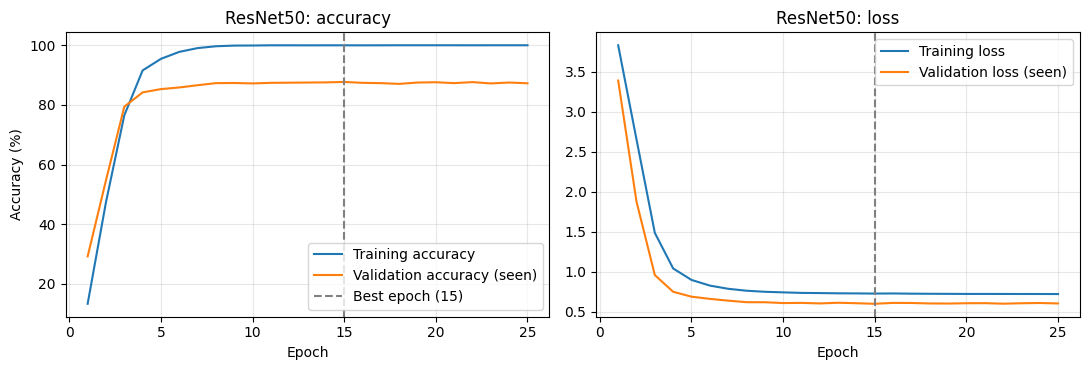

ResNet50: at best epoch train acc 99.99% vs val acc 87.70% (gap +12.29 pts)


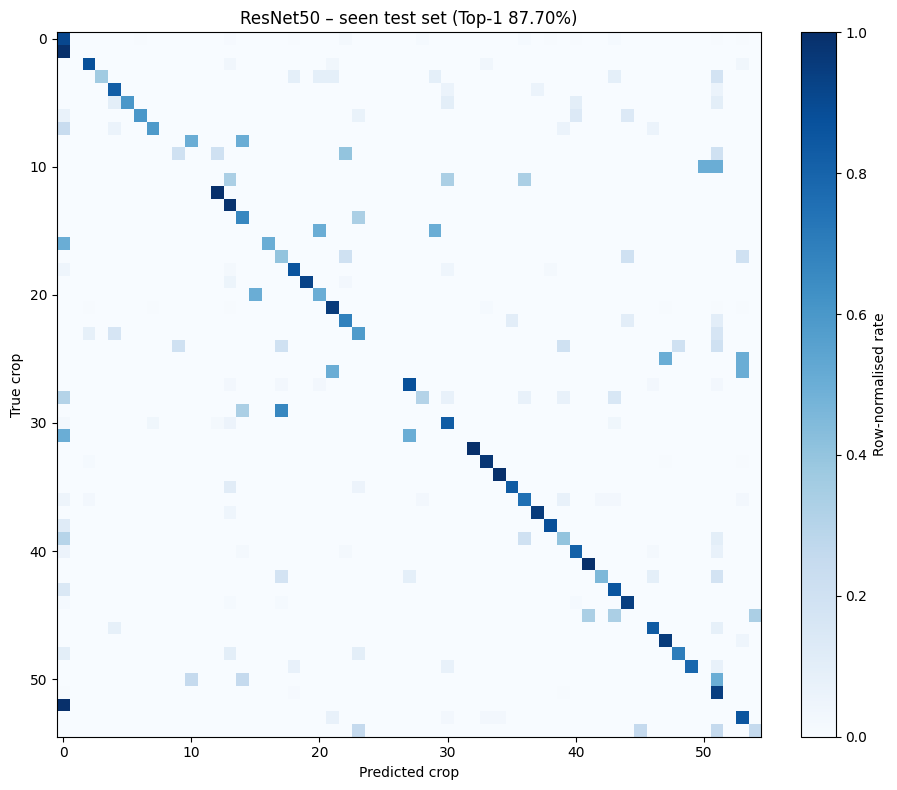

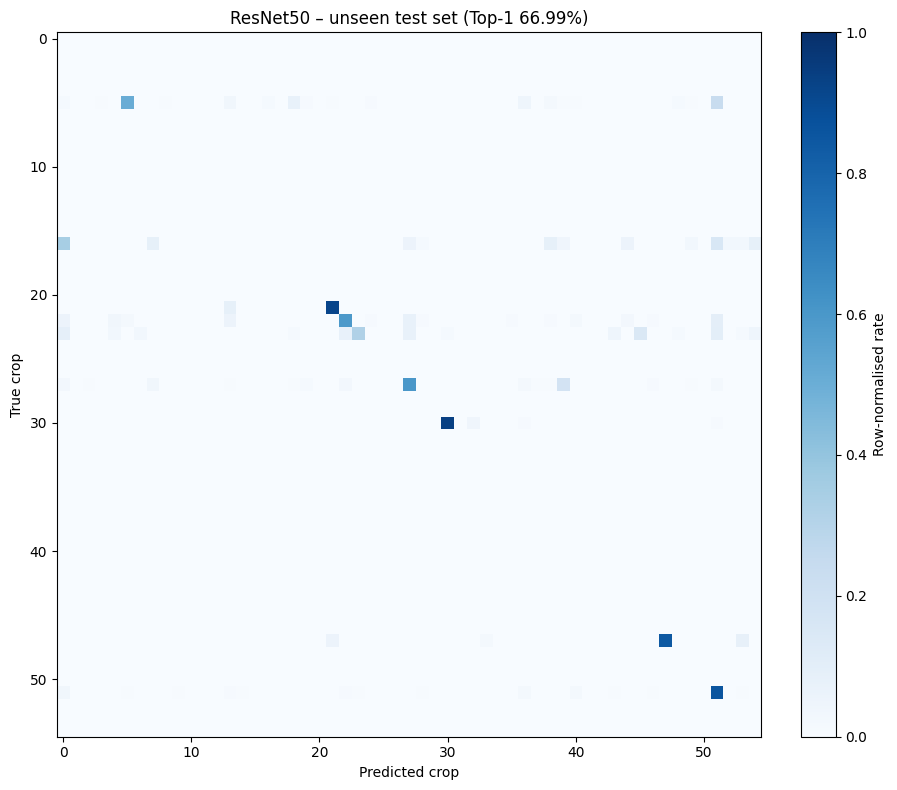

{
  "best_epoch": 15,
  "epochs_run": 25,
  "seen": {
    "1": 87.69999742507935,
    "3": 93.80000233650208,
    "5": 95.45000195503235
  },
  "unseen": {
    "1": 66.9889509677887,
    "3": 76.9336998462677,
    "5": 80.87016344070435
  },
  "harmonic": {
    "1": 75.95799038549414,
    "3": 84.53376378625647,
    "5": 87.55728241513613
  }
}

===== EfficientNet-B0 (efficientnet_b0) =====


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

EfficientNet-B0 ep1/30:   0%|          | 0/112 [00:00<?, ?it/s]

[EfficientNet-B0] ep 01 | train loss 2.8897 acc 40.69 | val(seen) loss 1.5205 acc 66.90 | 32s


...

[EfficientNet-B0] ep 20 | train loss 0.7241 acc 100.00 | val(seen) loss 0.6887 acc 86.25 | 27s


EfficientNet-B0 ep21/30:   0%|          | 0/112 [00:00<?, ?it/s]

[EfficientNet-B0] ep 21 | train loss 0.7240 acc 100.00 | val(seen) loss 0.6747 acc 86.95 | 27s


EfficientNet-B0 ep22/30:   0%|          | 0/112 [00:00<?, ?it/s]

[EfficientNet-B0] ep 22 | train loss 0.7232 acc 100.00 | val(seen) loss 0.6847 acc 86.65 | 26s
[EfficientNet-B0] early stopping at epoch 22 (no improvement for 10 epochs; best epoch 12, val acc 87.15)
[EfficientNet-B0] best model: epoch 12, val(seen) Top-1 87.15  -> saved to /content/drive/MyDrive/DPD_runs/crop_independent/EfficientNet-B0_best.pt


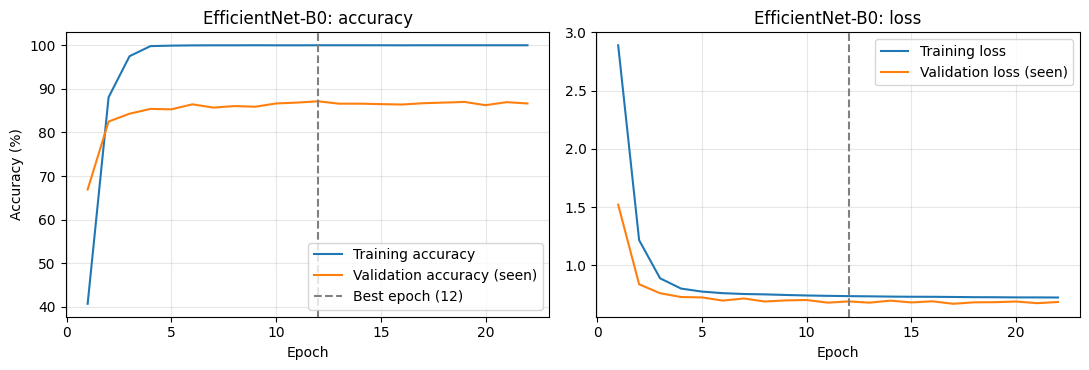

EfficientNet-B0: at best epoch train acc 100.00% vs val acc 87.15% (gap +12.85 pts)


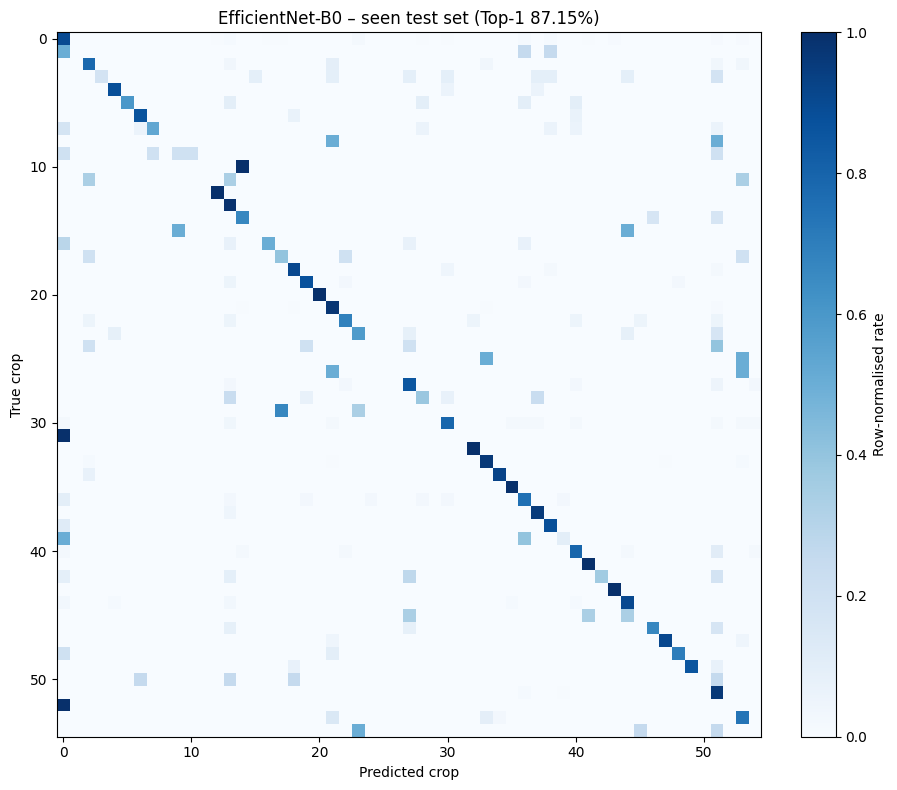

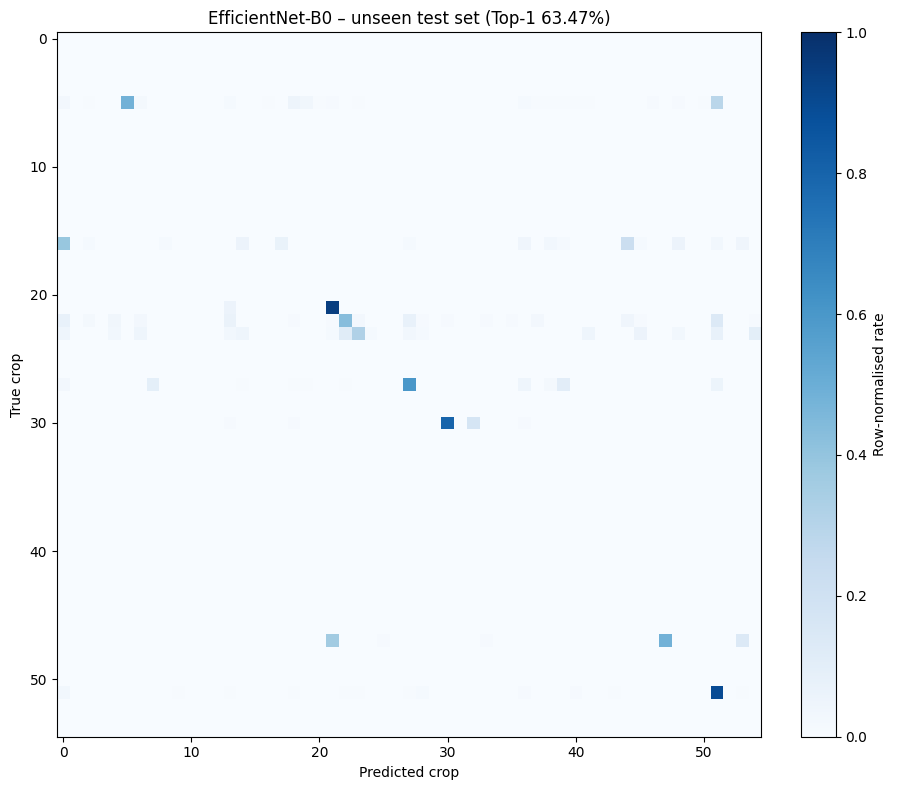

{
  "best_epoch": 12,
  "epochs_run": 22,
  "seen": {
    "1": 87.1500015258789,
    "3": 92.1999990940094,
    "5": 93.69999766349792
  },
  "unseen": {
    "1": 63.46685290336609,
    "3": 74.86187815666199,
    "5": 78.10773253440857
  },
  "harmonic": {
    "1": 73.44644592839295,
    "3": 82.63124073319771,
    "5": 85.19633368702037
  }
}

===== ConvNeXt-Tiny (convnext_tiny) =====


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

ConvNeXt-Tiny ep1/30:   0%|          | 0/112 [00:00<?, ?it/s]

/tmp/ipykernel_5913/1238051416.py:33: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


...

[ConvNeXt-Tiny] ep 17 | train loss 0.7141 acc 100.00 | val(seen) loss 0.4632 acc 91.55 | 42s


ConvNeXt-Tiny ep18/30:   0%|          | 0/112 [00:00<?, ?it/s]

[ConvNeXt-Tiny] ep 18 | train loss 0.7140 acc 100.00 | val(seen) loss 0.4653 acc 91.45 | 42s


ConvNeXt-Tiny ep19/30:   0%|          | 0/112 [00:00<?, ?it/s]

[ConvNeXt-Tiny] ep 19 | train loss 0.7139 acc 100.00 | val(seen) loss 0.4668 acc 91.50 | 42s
[ConvNeXt-Tiny] early stopping at epoch 19 (no improvement for 10 epochs; best epoch 9, val acc 91.80)
[ConvNeXt-Tiny] best model: epoch 9, val(seen) Top-1 91.80  -> saved to /content/drive/MyDrive/DPD_runs/crop_independent/ConvNeXt-Tiny_best.pt


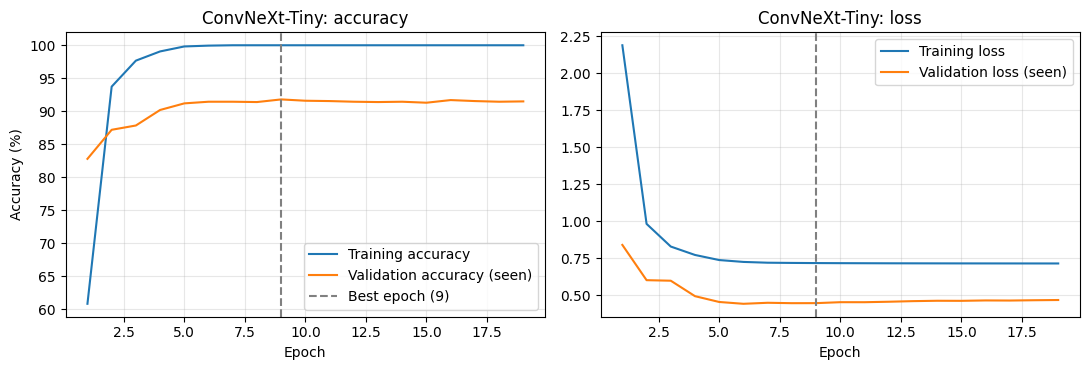

ConvNeXt-Tiny: at best epoch train acc 100.00% vs val acc 91.80% (gap +8.20 pts)


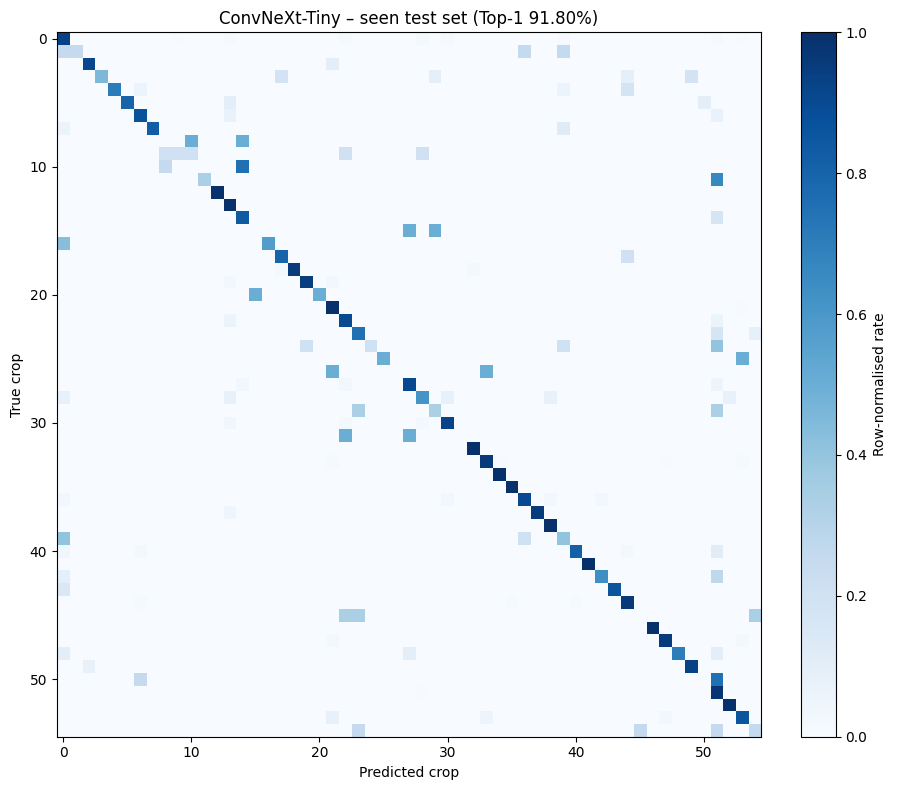

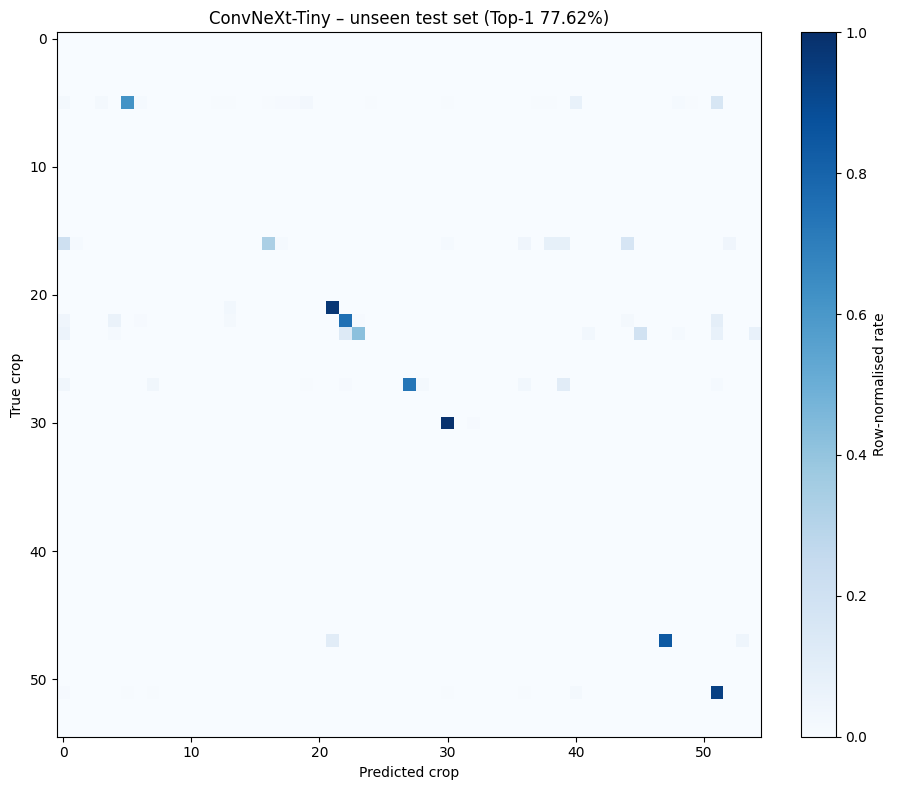

{
  "best_epoch": 9,
  "epochs_run": 19,
  "seen": {
    "1": 91.79999828338623,
    "3": 96.5499997138977,
    "5": 97.75000214576721
  },
  "unseen": {
    "1": 77.62430906295776,
    "3": 88.88121843338013,
    "5": 91.29834175109863
  },
  "harmonic": {
    "1": 84.11911549576519,
    "3": 92.55703219829932,
    "5": 94.41408391224562
  }
}


In [ ]:
results, curves, cms = {}, {}, {}
for name, (tid, lr) in MODELS.items():
    print(f"\n===== {name} ({tid}) =====")
    model, hist, best_ep = train_model(name, tid, lr)
    curves[name] = hist
    hist.to_csv(os.path.join(CFG["out_dir"], f"{name}_history.csv"), index=False)
    plot_curves(name, hist, best_ep)
    r = {"best_epoch": best_ep, "epochs_run": len(hist)}
    for split, dl in [("seen", dl_seen), ("unseen", dl_unseen)]:
        lg, yy = predict(model, dl)
        acc = topk_acc(lg, yy)
        r[split] = acc
        cm = confusion_matrix(yy.numpy(), lg.argmax(1).numpy(), labels=list(range(NUM_CLASSES)))
        cms[(name, split)] = cm
        pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
            os.path.join(CFG["out_dir"], f"{name}_{split}_confusion_matrix.csv"))
        plot_cm(cm, f"{name} – {split} test set (Top-1 {acc[1]:.2f}%)",
                os.path.join(CFG["out_dir"], f"{name}_{split}_confusion_matrix.png"))
    r["harmonic"] = {k: harmonic(r["seen"][k], r["unseen"][k]) for k in CFG["topk"]}
    results[name] = r
    print(json.dumps(r, indent=2))
    del model; torch.cuda.empty_cache()

json.dump(results, open(os.path.join(CFG["out_dir"], "results.json"), "w"), indent=2)

## 6. Summary

,Seen Top-1,Unseen Top-1,H Top-1,Seen Top-3,Unseen Top-3,H Top-3,Seen Top-5,Unseen Top-5,H Top-5
Model,,,,,,,,,
ResNet50,87.70,66.99,75.96,93.80,76.93,84.53,95.45,80.87,87.56
EfficientNet-B0,87.15,63.47,73.45,92.20,74.86,82.63,93.70,78.11,85.20
ConvNeXt-Tiny,91.80,77.62,84.12,96.55,88.88,92.56,97.75,91.30,94.41


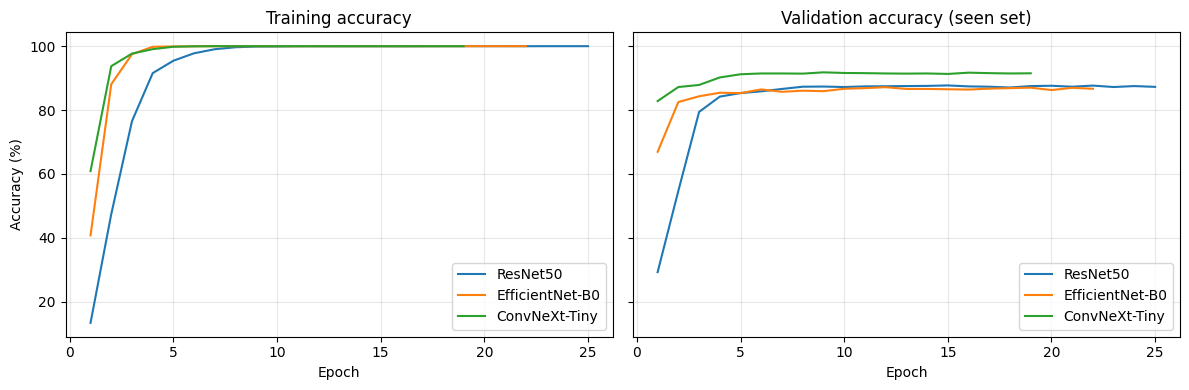

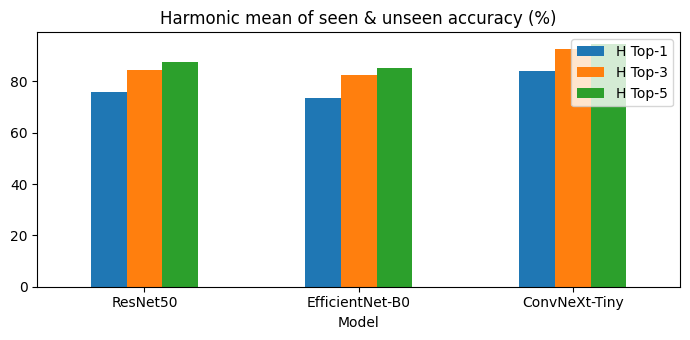

In [ ]:
rows = []
for name, r in results.items():
    row = {"Model": name}
    for k in CFG["topk"]:
        row[f"Seen Top-{k}"] = r["seen"][k]
        row[f"Unseen Top-{k}"] = r["unseen"][k]
        row[f"H Top-{k}"] = r["harmonic"][k]
    rows.append(row)
summary = pd.DataFrame(rows).set_index("Model").round(2)
summary.to_csv(os.path.join(CFG["out_dir"], "summary.csv"))
display(summary)

# all models: training vs validation accuracy
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for name, h in curves.items():
    l, = ax[0].plot(h["epoch"], h["train_acc"], label=name)
    ax[1].plot(h["epoch"], h["val_acc"], label=name, color=l.get_color())
ax[0].set_title("Training accuracy"); ax[1].set_title("Validation accuracy (seen set)")
for a in ax: a.set_xlabel("Epoch"); a.grid(alpha=.3); a.legend()
ax[0].set_ylabel("Accuracy (%)")
fig.tight_layout(); fig.savefig(os.path.join(CFG["out_dir"], "all_models_accuracy.png"), dpi=150); plt.show()

# bar chart of harmonic mean
summary[[f"H Top-{k}" for k in CFG["topk"]]].plot.bar(figsize=(7, 3.5), rot=0, title="Harmonic mean of seen & unseen accuracy (%)")
plt.tight_layout(); plt.savefig(os.path.join(CFG["out_dir"], "harmonic_mean.png"), dpi=150); plt.show()

### Notes for the report
- **Top-N accuracy**: a prediction counts as correct if the true crop is among the N highest-scored classes.
- **Harmonic mean** `H = 2SU/(S+U)` penalises models that do well on seen compositions but poorly on unseen ones.
- Confusion matrices are row-normalised (diagonal = per-class recall); raw counts are saved as CSV.
- Early stopping uses the **seen test set as the validation set** (patience 10, up to 30 epochs). Because the best epoch is picked on seen data, seen accuracy is slightly optimistic; the **unseen** set was never used for any decision, so it is the clean generalisation measure.
- No data augmentation or extra cleaning is applied (only conversion to tensors and normalisation, no resizing). Training accuracy is the running average over each epoch while weights are updating, so read the *gap* near the best epoch to judge over/under-fitting.
- Checkpoints (`<model>_best.pt`, with class names and architecture id), per-epoch history CSVs, metrics (`results.json`, `summary.csv`) and figures are saved to `out_dir`.